#  机器学习练习 Scikit-learn的介绍

Scikit-learn是基于NumPy、SciPy和Matplotlib的开源Python机器学习包，它封装了一系列数据预处理、机器学习算法、模型选择等工具，是数据分析师首选的机器学习工具包。

自2007年发布以来，Scikit-learn已经成为Python重要的机器学习库了，Scikit-learn简称sklearn，支持包括分类、回归、降维和聚类四大机器学习算法，还包括了特征提取、数据处理和模型评估三大模块。

在工程应用中，用python手写代码来从头实现一个算法的可能性非常低，这样不仅耗时耗力，还不一定能够写出构架清晰，稳定性强的模型。更多情况下，是分析采集到的数据，根据数据特征选择适合的算法，在工具包中调用算法，调整算法的参数，获取需要的信息，从而实现算法效率和效果之间的平衡。而sklearn，正是这样一个可以帮助我们高效实现算法应用的工具包。

sklearn有一个完整而丰富的官网，里面讲解了基于sklearn对所有算法的实现和简单应用。然而，这个官网是全英文的，并且现在没有特别理想的中文接口，市面上也没有针对sklearn非常好的书。因此，这次课目的就是向大家介绍sklearn的应用。

英文官方文档：https://scikit-learn.org/stable/

中文官方文档：https://scikit-learn.org.cn/

## 1.  Scikit-learn概述

Scikit-Learn (简称 Sklearn) 是基于 Python 语言的机器学习工具。它建立在 NumPy、
SciPy、Pandas和 Matplotlib 之上，对常用的机器学习方法进行了封装，例如，分类、回归、聚类、降维、模型评估、数据预处理等，我们只需调用对应的接口即可。

Scikit-Learn库的算法主要有四类：分类、回归、聚类、降维。其中：

1.  常用的回归：线性回归、决策树回归、SVM回归、KNN
    回归；集成回归：随机森林、Adaboost、GradientBoosting、Bagging、ExtraTrees。

2.  常用的分类：线性分类、决策树、SVM、KNN，朴素贝叶斯；集成分类：随机森林、Adaboost、GradientBoosting、Bagging、ExtraTrees。

3.  常用聚类：K均值(K-means)、层次聚类(Hierarchical clustering)、DBSCAN。

4.  常用降维：LinearDiscriminantAnalysis、PCA。

![](images/sklearn.jpeg)

上图代表了Scikit-Learn算法选择的一个简单路径，这个路径图代表：蓝色圆圈是判断条件，绿色方框是可以选择的算法，我们可以根据自己的数据特征和任务目标去找一条自己的操作路线。

Scikit-Learn中包含众多数据预处理和特征工程相关的模块，但其实Sklearn六大板块中有两块都是关于数据预处理和特征工程的，两个板块互相交互，为建模之前的全部工程打下基础。

## 2.Scikit-learn主要用法

### 2.1 基本建模符号

基本建模的符号标记见表3-1：


| 符号    | 代表含义 | 符号    | 代表含义   |
|---------|----------|---------|------------|
| X_train | 训练数据 | y_train | 训练集标签 |
| X_test  | 测试数据 | y_test  | 测试集标签 |
| X       | 完整数据 | y       | 数据标签   |
|         |          | y_pred  | 预测标签   |

### 2.1.1 导入工具包

导入工具包的方法如下(这里使用伪代码)：

`from sklearn import 包名称`

`from sklearn.库名称 import 包名称`

代码示例：

In [8]:
from sklearn import datasets, preprocessing  
#导入数据集，数据预处理库  
from sklearn.model_selection import train_test_split    
#从模型选择库导入数据切分包  
from sklearn.linear_model import LinearRegression    
#从线性模型库导入线性回归包  
from sklearn.metrics import r2_score  
#从评价指标库导入R2评价指标  

import numpy as np
np.set_printoptions(precision=5,suppress=True)

### 2.1.2 导入数据

导入数据的方法如下：

`from sklearn.datasets import 数据名称`

Scikit-learn支持以NumPy的arrays对象、Pandas对象、SciPy的稀疏矩阵及其他可转换为数值型arrays的数据结构作为其输入，前提是数据必须是数值型的。

sklearn.datasets模块提供了一系列加载和获取著名数据集如鸢尾花、波士顿房价、Olivetti人脸、MNIST数据集等的工具，也包括了一些toy
data如S型数据等的生成工具。

Scikit-learn内置了很多可以用于机器学习的数据，可以用两行代码就可以使用这些数据。内置数据分为可以直接使用的数据集、需下载的数据集以及生成数据集。

- 1.可以直接使用的自带数据集

此类数据集可以直接导入使用数据，数据集和描述见下表：


| 数据集名称               | 描述           | 类型       | 维度           |
|--------------------------|----------------|------------|----------------|
| load_boston              | Boston房屋价格 | 回归       | 506\*13        |
| fetch_california_housing | 加州住房       | 回归       | 20640\*9       |
| load_diabetes            | 糖尿病         | 回归       | 442\*10        |
| load_digits              | 手写字         | 分类       | 1797\*64       |
| load_breast_cancer       | 乳腺癌         | 分类、聚类 | (357+212)\*30  |
| load_iris                | 鸢尾花         | 分类、聚类 | (50\*3)\*4     |
| load_wine                | 葡萄酒         | 分类       | (59+71+48)\*13 |
| load_linnerud            | 体能训练       | 多分类     | 20             |

- 2.需要下载的自带数据集

此类数据集第一次使用，需要联网下载数据，数据集和描述见下表：


| 数据集名称                    | 描述                                                                                                                                                                                                             |
|-------------------------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| fetch_20newsgroups            | 用于文本分类、文本挖据和信息检索研究的国际标准数据集之一。数据集收集了大约20,000左右的新闻组文档，均匀分为20个不同主题的新闻组集合。返回一个可以被文本特征提取器                                                 |
| fetch_20newsgroups_vectorized | 这是上面这个文本数据的向量化后的数据，返回一个已提取特征的文本序列，即不需要使用特征提取器                                                                                                                       |
| fetch_california_housing      | 加利福尼亚的房价数据，总计20640个样本，每个样本8个属性表示，以及房价作为target，所有属性值均为number，详情可调用。如：fetch_california_housing( )['DESCR']，了解每个属性的具体含义；                             |
| fetch_covtype                 | 森林植被类型，总计581012个样本，每个样本由54个维度表示(12个属性，其中2个分别是onehot4维和onehot40维)，以及target表示植被类型1-7，所有属性值均为number，详情可调用fetch_covtype( )['DESCR']了解每个属性的具体含义 |
| fetch_kddcup99                | KDD竞赛在1999年举行时采用的数据集，KDD99数据集仍然是网络入侵检测领域的事实Benckmark，为基于计算智能的网络入侵检测研究奠定基础，包含41项特征                                                                      |
| fetch_lfw_pairs               | 该任务称为人脸验证：给定一对两张图片，二分类器必须预测这两个图片是否来自同一个人。                                                                                                                               |
| fetch_lfw_people              | 打好标签的人脸数据集                                                                                                                                                                                             |
| fetch_mldata                  | 从 mldata.org 中下载数据集                                                                                                                                                                                       |
| fetch_olivetti_faces          | Olivetti 脸部图片数据集                                                                                                                                                                                          |
| fetch_rcv1                    | 路透社新闻语聊数据集                                                                                                                                                                                             |
| fetch_species_distributions   | 物种分布数据集                                                                                                                                                                                                   |

- 3.生成数据集

此类数据集可以用来分类任务，可以用来回归任务，可以用来聚类任务，用于流形学习的，用于因子分解任务的，用于分类任务和聚类任务的：这些函数产生样本特征向量矩阵以及对应的类别标签集合，数据集和描述见下表：


| 数据集名称              | 描述                                                                                                                       |
|-------------------------|----------------------------------------------------------------------------------------------------------------------------|
| make_blobs              | 多类单标签数据集，为每个类分配一个或多个正态分布的点集                                                                     |
| make_classification     | 多类单标签数据集，为每个类分配一个或多个正态分布的点集，提供了为数据添加噪声的方式，包括维度相关性，无效特征以及冗余特征等 |
| make_gaussian-quantiles | 将一个单高斯分布的点集划分为两个数量均等的点集，作为两类                                                                   |
| make_hastie-10-2        | 产生一个相似的二元分类数据集，有10个维度                                                                                   |
| make_circle和make_moons | 产生二维二元分类数据集来测试某些算法的性能，可以为数据集添加噪声，可以为二元分类器产生一些球形判决界面的数据               |

代码示例：

In [14]:
#导入内置的Boston房屋价格数据集
from sklearn.datasets import load_boston

boston = load_boston()#加载数据

In [15]:
#数据是以「字典」格式存储的，看看Boston房屋价格数据集的键值有哪些。
boston.keys()

dict_keys(['data', 'target', 'feature_names', 'DESCR', 'filename'])

In [16]:
#定义数据、标签
X = boston.data
y = boston.target

In [17]:
X.shape

(506, 13)

In [18]:
y.shape

(506,)

In [19]:
boston['feature_names']

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT'], dtype='<U7')

In [20]:
# 查看boston数据集的房屋价格
print("数据标签:", boston.target[0:10]) 

数据标签: [24.  21.6 34.7 33.4 36.2 28.7 22.9 27.1 16.5 18.9]


## 2.2 数据预处理

### 2.2.1 数据划分

机器学习的数据，可以划分为训练集、验证集和测试集，也可以划分为训练集和测试集。

![](images/8dcde98a61699afa97dc30596cbc71d5.png)


代码示例：

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X,#可以是列表、numpy数组、scipy稀疏矩阵或pandas的DataFrame
                                                    y,#可以是列表、numpy数组、scipy稀疏矩阵或pandas的DataFrame
                                                    random_state=12,#若为整数时，每次生成的数据都相同
                                                    test_size=0.3)#0.0到1.0之间
# 参数test_size, 将完整数据集的70%作为训练集，30%作为测试集，

参考资料：

https://scikit-learn.org.cn/view/649.html

https://www.geeksforgeeks.org/how-to-implement-stratified-sampling-with-scikit-learn/

https://www.cnblogs.com/Yanjy-OnlyOne/p/11288098.html

- 数据集拆分是为了验证模型在训练集和测试集是否过拟合，使用train_test_split的目的是保证从数据集中均匀拆分出测试集。这里，简单把30%的数据集拿出来用作测试集。

- 使得测试集和训练集中各类别数据的比例与原始数据集比例一致(stratify分层策略)，因此，对于所有分类问题，建议都设置 stratify = y

- 可通过设置shuffle=True 提前打乱数据。

-  使用pandas查看数据（可选内容），这部分自学

In [23]:
import pandas as pd

In [24]:
boston_df=pd.DataFrame(boston.data)
boston_df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33


In [25]:
boston_df['label']=boston.target#增加一列
boston_df

,0,1,2,3,4,5,6,7,8,9,10,11,12,label
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48,22.0


In [26]:
column_name = boston['feature_names'].tolist()
column_name.append('label')
column_name

['CRIM',
 'ZN',
 'INDUS',
 'CHAS',
 'NOX',
 'RM',
 'AGE',
 'DIS',
 'RAD',
 'TAX',
 'PTRATIO',
 'B',
 'LSTAT',
 'label']

In [27]:
boston_df.columns=column_name
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,label
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [28]:
boston_df.shape

(506, 14)

In [29]:
cols = boston_df.shape[1]
cols

14

In [30]:
# set X (training data) and y (target variable)

X = boston_df.iloc[:,:-1]#X是所有行，去掉最后一列
y = boston_df.iloc[:,-1]#X是所有行，最后一列
#下面的代码作用一样
#X = cancer_df.iloc[:,:cols-1]#X是所有行，去掉最后一列
#y = cancer_df.iloc[:,cols-1:]#X是所有行，最后一列

In [31]:
X.shape

(506, 13)

In [32]:
y.shape

(506,)

### 2.2.2 数据变换操作

sklearn.preprocessing模块包含了数据变换的主要操作（表3-5），数据变换的方法如下：

`from sklearn.preprocessing import 库名称`

下表使用Scikit-learn进⾏数据变换

| 预处理操作           | 库名称             |
|----------------------|--------------------|
| 标准化               | StandardScaler     |
| 最小最大标准化       | MinMaxScaler       |
| One-Hot编码          | OneHotEncoder      |
| 归一化               | Normalizer         |
| 二值化(单个特征转换) | Binarizer          |
| 标签编码             | LabelEncoder       |
| 缺失值填补           | Imputer            |
| 多项式特征生成       | PolynomialFeatures |

代码示例：

In [34]:
#使⽤Scikit-learn进⾏数据标准化
from sklearn.preprocessing import StandardScaler,MinMaxScaler
#构建转换器实例
scaler = MinMaxScaler()#实例化

In [35]:
#拟合及转换
X_train = scaler.fit_transform(X_train)#转换训练数据
print("X_train.shape is : ", X_train.shape)
X_test = scaler.fit_transform(X_test)#转换测试数据
print("X_test.shape is : ", X_test.shape)

X_train.shape is :  (354, 13)
X_test.shape is :  (152, 13)


### 2.2.3 特征选择

特征选择的方法如下：

#导入特征选择库

`from sklearn import feature_selection as fs`

-   过滤式(Filter)

#保留得分排名前k的特征(top k方式)

`fs.SelectKBest(score_func, k)`

#交叉验证特征选择

`fs.RFECV(estimator, scoring=“r2”)`

-   封装式(Wrapper)，结合交叉验证的递归特征消除法，自动选择最优特征个数：

`fs.SelectFromModel(estimator)`

-   嵌入式(Embedded)，从模型中自动选择特征，任何具有coef_或者feature_importances_的基模型都可以作为estimator参数传入。

In [37]:
#from sklearn.feature_selection import SelectKBest,chi2 # 分类问题使用这个
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression #回归问题使用这个

-   对于回归问题: score_func可以选择f_regression 或者 mutual_info_regression


-   对于分类问题: score_func可以选择chi2, f_classif 或者 mutual_info_classif

In [38]:
# 初始化 SelectKBest 并指定评分函数和要选择的特征数
selector = SelectKBest(score_func=f_regression, k=4)
# 拟合和转换数据 
X_train_new = selector.fit_transform(X_train, y_train)

In [39]:
X_train_new.shape

(354, 4)

In [40]:
boston['feature_names'] 

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT'], dtype='<U7')

In [41]:
# 获取被选中的特征的布尔掩码  
support = selector.get_support()
# boston['feature_names']存储的是特征名  
selected_feature_names = [name for name, selected in zip(boston['feature_names'], support) if selected] 
# 输出被选中的特征名  
print(selected_feature_names)
#print(boston['feature_names'])
#print(support)

['RM', 'TAX', 'PTRATIO', 'LSTAT']


In [42]:
support

array([False, False, False, False, False,  True, False, False, False,
        True,  True, False,  True])

In [43]:
selector.scores_ #越大说明特征越重要

array([ 59.2033 ,  48.15474,  96.58355,  13.23903,  94.71613, 330.24334,
        60.44772,  29.40503,  57.27253,  99.24894, 101.44353,  47.67957,
       474.34351])

In [44]:
selector.pvalues_ #越小说明特征越重要

array([0.     , 0.     , 0.     , 0.00032, 0.     , 0.     , 0.     ,
       0.     , 0.     , 0.     , 0.     , 0.     , 0.     ])

In [45]:
selector.n_features_in_#特征的数量

13

使用拟合后的SelectKBest来转换测试数据，以选取相同的特征

In [46]:
X_test_new = selector.transform(X_test)
#X_test_new
#X_test[:,7]
#X_test[:,-3]

In [47]:
X_test_new.shape

(152, 4)

### 2.2.4 可视化训练数据

In [48]:
import matplotlib.pyplot as plt

In [49]:
boston['feature_names'] 

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT'], dtype='<U7')

In [50]:
feature_names = boston['feature_names']
feature_names

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT'], dtype='<U7')

In [51]:
selected_feature_names

['RM', 'TAX', 'PTRATIO', 'LSTAT']

- 采用散点图可视化四个最重要的特征与价格之间的关系，X_train_new 存储的是被筛选出来的特征

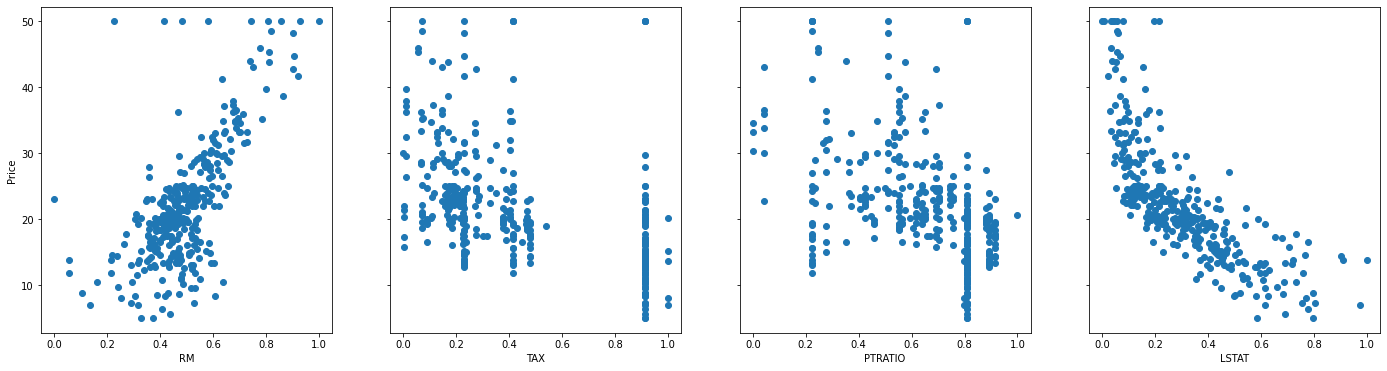

In [52]:
fig,ax=plt.subplots(1, 4, figsize=(24, 6), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train_new[:,i],y_train)#X_train_new 表示被筛选出来的特征
    ax[i].set_xlabel(selected_feature_names[i])
ax[0].set_ylabel("Price")
plt.show()

In [53]:
X_train_new[:,1].shape

(354,)

- 采用散点图依次可视化所有特征与价格之间的关系

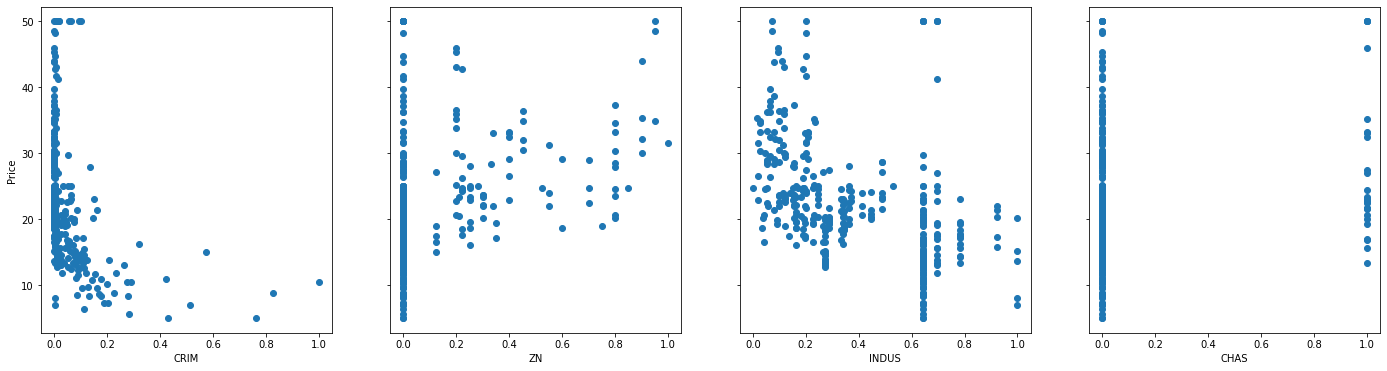

In [54]:
fig,ax=plt.subplots(1, 4, figsize=(24, 6), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i],y_train)# 0-3个特征
    ax[i].set_xlabel(feature_names[i])
ax[0].set_ylabel("Price")
plt.show()

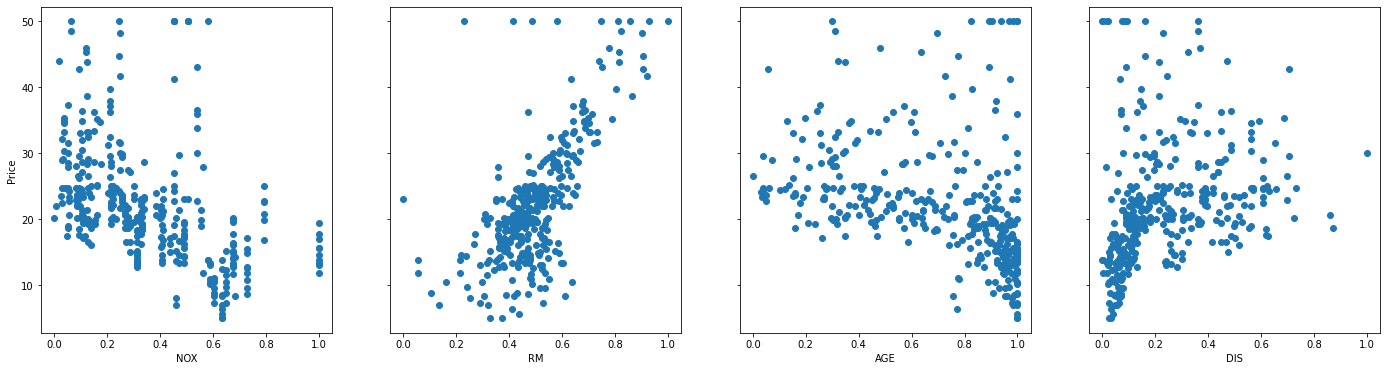

In [55]:
fig,ax=plt.subplots(1, 4, figsize=(24, 6), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i+4],y_train)#  i+4  表示 4-7个特征
    ax[i].set_xlabel(feature_names[i+4])
ax[0].set_ylabel("Price")
plt.show()

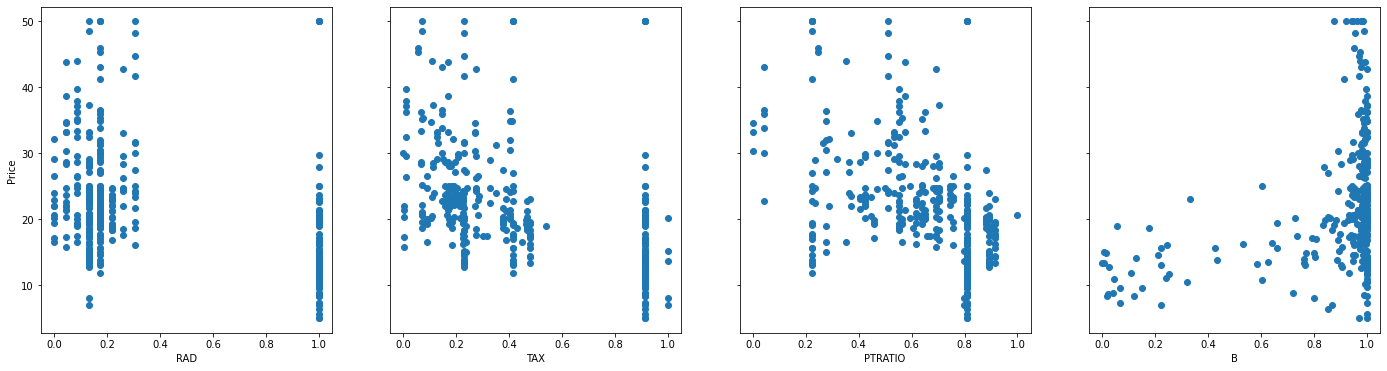

In [56]:
fig,ax=plt.subplots(1, 4, figsize=(24, 6), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i+8],y_train)#  i+8  表示 8-11个特征
    ax[i].set_xlabel(feature_names[i+8])
ax[0].set_ylabel("Price")
plt.show()

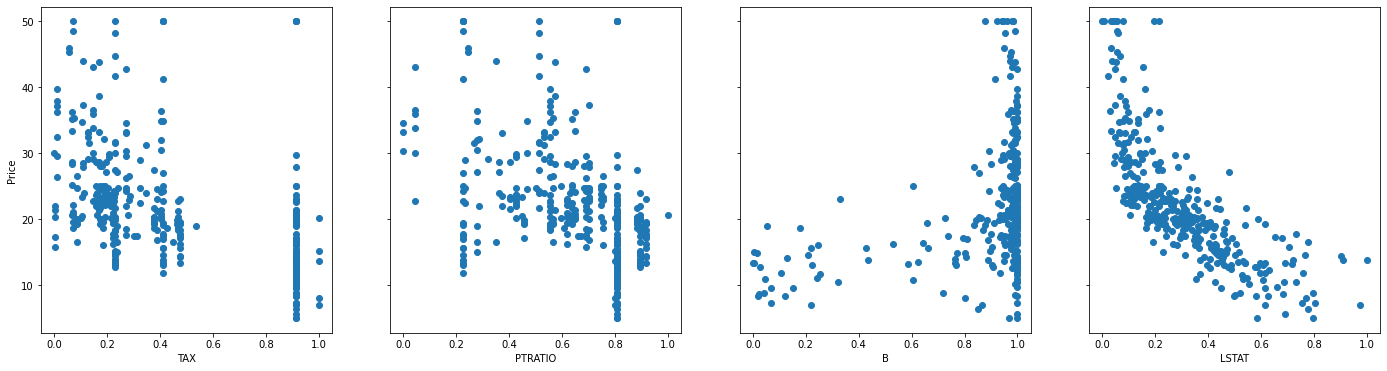

In [59]:
fig,ax=plt.subplots(1, 4, figsize=(24, 6), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i+9],y_train)#  i+9  表示 9-12个特征
    ax[i].set_xlabel(feature_names[i+9])
ax[0].set_ylabel("Price")
plt.show()

In [60]:
X_train.shape

(354, 13)

## 2.3 监督学习算法

### 2.3.1 监督学习算法-回归

常见的回归模型

| 回归模型名称   | 库名称                     |
|----------------|----------------------------|
| 线性回归       | LinearRegression           |
| 岭回归         | Ridge                      |
| LASSO回归      | LASSO                      |
| ElasticNet回归 | ElasticNet                 |
| 决策树回归     | tree.DecisionTreeRegressor |

代码示例：

In [61]:
#从线性模型库导入线性回归模型
from sklearn.linear_model import LinearRegression
# 构建模型实例
model = LinearRegression(normalize=False)

- 使用筛选出的4个最重要的特征训练模型

In [62]:
# 训练模型
model.fit(X_train_new, y_train)
# 作出预测
y_pred = model.predict(X_test_new)

In [63]:
#从评价指标库导入MSE
from sklearn.metrics import mean_squared_error

In [64]:
err_test = mean_squared_error(y_pred,y_test)
print(f'test err: {err_test:.2f}')

test err: 28.13


In [65]:
#查看学习到的参数
model.coef_ 

array([ 20.70992,  -1.13162,  -7.19039, -21.28612])

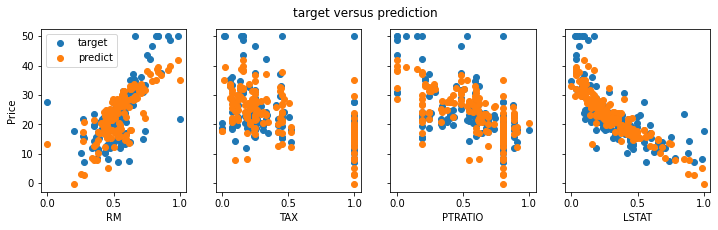

In [66]:
# plot predictions and targets versus original features  
#dlblue = '#0096ff'; dlorange = '#FF9300'; dldarkred='#C00000'; dlmagenta='#FF40FF'; dlpurple='#7030A0'; 
fig,ax=plt.subplots(1,4,figsize=(12, 3),sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_test_new[:,i],y_test, label = 'target')
    ax[i].set_xlabel(selected_feature_names[i])
    ax[i].scatter(X_test_new[:,i],y_pred, label = 'predict')#color=dlorange, 
ax[0].set_ylabel("Price"); ax[0].legend();
fig.suptitle("target versus prediction")
plt.show()

-  使用数据中的所有特征训练模型

In [67]:
y_test.shape

(152,)

In [68]:
#从线性模型库导入线性回归模型
from sklearn.linear_model import LinearRegression
# 构建模型实例
model= LinearRegression()
# 训练模型
model.fit(X_train, y_train)
# 作出预测
y_pred = model.predict(X_test)

In [69]:
err_test = mean_squared_error(y_pred,y_test)
print(f'test err: {err_test:.2f}')

test err: 27.79


In [70]:
#查看学习到的参数
model.coef_ 

array([ -9.17963,   5.37615,   1.76958,   3.34096,  -8.37307,  17.39316,
         1.93604, -14.84875,   7.42863,  -7.22993,  -7.36616,   4.13486,
       -22.06442])

## 2.4 交叉验证


交叉验证的方法如图，具体原理在第7章“机器学习实践”中有讲解，本章仅讲解使用方法。

![](images/2daa4a9b0a9881b23397ae6ddca0ff53.png)


代码示例：

- 首先需要重新加载和处理数据

In [90]:
#导入内置的Boston房屋价格数据集
from sklearn.datasets import load_boston

boston = load_boston()#加载数据
X = boston.data
y = boston.target

In [82]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler
#构建转换器实例
scaler = MinMaxScaler()#实例化
#scaler = StandardScaler()#实例化
X = scaler.fit_transform(X)

In [83]:
#从线性模型库导入线性回归模型
from sklearn.linear_model import LinearRegression
# 构建模型实例
model = LinearRegression(normalize=False)

In [84]:
X.shape

(506, 13)

In [85]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.metrics import mean_squared_error  

-  使用循环手动实现K折交叉验证

In [86]:
# 使用K折交叉验证（K-Fold Cross-Validation）  
kf = KFold(n_splits=5, shuffle=True, random_state=1)  # 分成5份，打乱数据  

# 存储每次交叉验证的得分  
scores = []  

# 进行交叉验证  
for train_index, test_index in kf.split(X):  
    X_train, X_test = X[train_index], X[test_index]  
    y_train, y_test = y[train_index], y[test_index]  
      
    model.fit(X_train, y_train)  # 训练模型  
    y_pred = model.predict(X_test)  # 预测  
      
    # 计算并存储均方误差（MSE）  
    score = mean_squared_error(y_test, y_pred)  
    scores.append(score)  
  
  # 输出每次交叉验证的得分和平均得分  
print("Cross-validation scores:", scores)  
print("Mean cross-validation score:", np.mean(scores))

Cross-validation scores: [23.380836480270183, 28.61431212797539, 15.16060657342218, 27.208219942688395, 23.371172592726857]
Mean cross-validation score: 23.547029543416603


-  使用cross_validate函数实现自动K折交叉验证

In [92]:
# 设置交叉验证策略  
kf = KFold(n_splits=5, shuffle=True, random_state=1)  
# 定义评估指标  
scoring = ['neg_mean_squared_error'] 
# 执行交叉验证  
results = cross_validate(model, X, y, cv=kf, scoring=scoring, return_train_score=True)
# 输出交叉验证结果，注意要将负MSE转换为正的MSE  
print("Cross-validation results:")  
print(f"Test Negative MSE Scores: {results['test_neg_mean_squared_error']}")  
test_mse_scores = -results['test_neg_mean_squared_error']  # 转换为正的MSE  
mean_test_mse = np.mean(test_mse_scores)  # 计算平均MSE  
print(f"Test MSE Scores: {test_mse_scores}")  
print(f"Mean Test MSE: {mean_test_mse}")  

Cross-validation results:
Test Negative MSE Scores: [-23.38084 -28.61431 -15.16061 -27.20822 -23.37117]
Test MSE Scores: [23.38084 28.61431 15.16061 27.20822 23.37117]
Mean Test MSE: 23.547029543416603


In [93]:
results

{'fit_time': array([0.001, 0.   , 0.001, 0.   , 0.001]),
 'score_time': array([0.   , 0.001, 0.   , 0.001, 0.   ]),
 'test_neg_mean_squared_error': array([-23.38084, -28.61431, -15.16061, -27.20822, -23.37117]),
 'train_neg_mean_squared_error': array([-21.86279, -20.50291, -23.79374, -20.81849, -21.6071 ])}

In [94]:
train_mse_scores = -results['train_neg_mean_squared_error']  # 转换为正的MSE  
mean_train_mse = np.mean(train_mse_scores)  # 计算平均训练集MSE  
print(f"Train MSE Scores: {train_mse_scores}")  
print(f"Mean Train MSE: {mean_train_mse}")

Train MSE Scores: [21.86279 20.50291 23.79374 20.81849 21.6071 ]
Mean Train MSE: 21.717008513531052


In [95]:
results

{'fit_time': array([0.001, 0.   , 0.001, 0.   , 0.001]),
 'score_time': array([0.   , 0.001, 0.   , 0.001, 0.   ]),
 'test_neg_mean_squared_error': array([-23.38084, -28.61431, -15.16061, -27.20822, -23.37117]),
 'train_neg_mean_squared_error': array([-21.86279, -20.50291, -23.79374, -20.81849, -21.6071 ])}

## 2.5 评价指标

sklearn.metrics模块包含了一系列用于评价模型的评分函数、损失函数以及成对数据的距离度量函数。评价指标主要分为分类评价指标、回归评价指标等等，这里列举了常见的几种评价指标。

评价指标使用的方法如下：

`from sklearn.metrics import 库名称`


| 评价指标             | 库名称                | 使用范围 |
|----------------------|-----------------------|----------|
| 正确率               | accuracy_score        | 分类     |
| 精确率               | precision_score       | 分类     |
| F1 值                | f1_score              | 分类     |
| 对数损失             | log_loss              | 分类     |
| 混淆矩阵             | confusion_matrix      | 分类     |
| 含多种评价的分类报告 | classification_report | 分类     |
| 均方误差MSE          | mean_squared_error    | 回归     |
| 平均绝对误差MAE      | mean_absolute_error   | 回归     |
| 决定系数R2           | r2_score              | 回归     |

代码示例：

### 下面的代码仅仅用做讲解使用，运行可能会出错！！！

In [ ]:
#从评价指标库导入准确率
from sklearn.metrics import accuracy_score
#计算样本的准确率
accuracy_score(y_test, y_pred)
#对于测试集而言，大部分函数都必须包含真实值y_test和预测值y_pred

In [ ]:
#从模型选择库导入交叉验证分数  
from sklearn.model_selection import cross_val_score    
clf = DecisionTreeClassifier(max_depth=5)  
#使用5折交叉验证对决策树模型进行评估，使用的评分函数为F1值  
scores = cross_val_score(clf, X_train, y_train,cv=5, scoring='f1_weighted')

## 3.Scikit-learn总结

Scikit-learn是基于 Python 语言的机器学习工具，它建立在 NumPy、SciPy、Pandas和Matplotlib之上，被广泛地用于统计分析和机器学习建模等数据科学领域，其主要优点包括：

- 建模方便：用户通过Scikit-learn能够实现各种监督和非监督学习的模型，仅仅需要几行代码就可以实现。
- 功能多样：使用Scikit-learn还能够进行数据的预处理、特征工程、数据集切分、模型评估等工作。
- 数据丰富：内置丰富的数据集，比如：泰坦尼克、鸢尾花等，还可以生成数据，非常方便。

参考文献

[1] PEDREGOSA F, VAROQUAUX G, GRAMFORT A, et al. Scikit-learn: Machine Learning
in Python[J]. Journal of Machine Learning Research, 2011, 12: 2825–2830.

[2] Andrew Ng. Machine Learning[EB/OL]. StanfordUniversity,2014.https://www.coursera.org/course/ml